# 🔗 링크 예측 예제 — 트러스의 누락 부재 찾기

**건설빅데이터분석 · 그래프 신경망 · W09 링크 예측 · 예제 노트북 (실행 결과 포함)**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/baekja/Lecture_GNN-AE-Practice/blob/main/PyG_LinkPred_Truss/truss_linkpred_example.ipynb)

> 도면을 디지털로 옮기거나 스캔 데이터로 구조 모델을 만들다 보면 **부재가 빠지는** 일이 생깁니다.
> 트러스를 그래프(절점 = 노드, 부재 = 엣지)로 보면 "빠진 부재 찾기"는 곧 **링크 예측**입니다.
> 이 노트북은 Pratt · Howe 트러스 60동을 직접 만들어 강의노트의 방법 — **휴리스틱 · GAE · VGAE · SEAL** — 을 모두 적용하고,
> 마지막에 **직접강성법 구조해석**으로 복원한 트러스를 검증합니다.

| 절 | 내용 | 강의노트 |
|:-:|---|:-:|
| 1–2 | 트러스 생성 · 그래프 변환 · Maxwell 정정 조건 | 1절 |
| 3 | 문제 세우기 — 시험 트러스에서 부재 20% 가리기 | 1 · 7.4절 |
| 4 | 기준선 — 공통 이웃 · Jaccard · Adamic–Adar · Katz · 거리 · 차수 결손 | 2절 |
| 5 | GAE · VGAE — 완전한 트러스에서 부재를 가려 가며 학습 (귀납) | 4 · 5 · 7.4절 |
| 6 | 채점 — AUC · AP · Hits@K(무작위 음성)와 대각재 방향(어려운 음성) | 7절 |
| 7 | 구조 검증 — 예측으로 복원한 트러스를 직접강성법으로 해석 | — |
| 8 | 고쳐 보기 ① — MLP 디코더 + 어려운 음성 | 4.3 · 7.5절 |
| 9 | 고쳐 보기 ② — SEAL 간이판(부분그래프 + DRNL) · 한 표로 비교 | 6절 |
| 10 | 시드 3개로 다시 | 7.5절 |

**사용법** — Colab에서 **파일 → Drive에 사본 저장** 후 위에서부터 차례대로 실행(`Shift + Enter`). GPU는 필요 없습니다(CPU 런타임 그대로).

## 0. 준비 — PyG 설치와 라이브러리
PyG가 없으면 설치하고(Colab), 오늘 쓸 도구를 불러옵니다.

In [1]:
import importlib.util, subprocess
if importlib.util.find_spec("torch_geometric") is None:           # Colab 처음 실행이면 PyG 설치
    subprocess.run(["pip", "install", "-q", "torch_geometric"], check=True)

import time, math, warnings, contextlib, io
warnings.filterwarnings("ignore")                                   # 선택 확장 모듈 안내 등 경고 숨김
from collections import deque
import numpy as np, pandas as pd, networkx as nx, matplotlib.pyplot as plt
import torch, torch_geometric as pyg
from torch import nn
from torch_geometric.nn import GAE, VGAE, GCN, GCNConv, global_mean_pool, global_max_pool
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.utils import to_undirected, degree
from sklearn.metrics import roc_auc_score, average_precision_score
print("torch", torch.__version__, "| PyG", pyg.__version__)
T0 = time.time()                                                    # ⏱ 노트북 전체 시간

torch 2.14.1 | PyG 2.8.1


## 1. 트러스 만들기 — Pratt와 Howe
평행현 트러스: 아래현 절점 `0..n`, 위현 절점 `n+1..2n+1`. 부재 = 아래현 n + 위현 n + 수직재 n+1 + **대각재 n**.
- **Pratt**: 대각재가 경간 중앙 쪽으로 **내려간다**(중력 하중에서 인장)
- **Howe**: 대각재가 경간 중앙 쪽으로 **올라간다**(압축)
- 두 형식은 **대각재 방향만** 다르다 → 한 패널에서 "어느 대각선이 부재인가"는 거리만으로는 알 수 없다(6절)

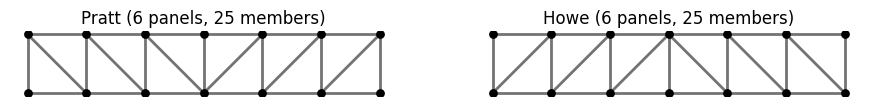

In [2]:
def make_truss(kind, n, w, h):
    """평행현 트러스. 반환: 절점 좌표(m), 부재 목록, 대각재 목록, 같은 패널의 '반대 대각선' 목록"""
    pos = np.array([(i * w, 0.0) for i in range(n + 1)] + [(i * w, h) for i in range(n + 1)])
    b, t = (lambda i: i), (lambda i: n + 1 + i)                     # 아래 · 위 절점 번호
    members = ([(b(i), b(i + 1)) for i in range(n)] + [(t(i), t(i + 1)) for i in range(n)]
               + [(b(i), t(i)) for i in range(n + 1)])               # 아래현 · 위현 · 수직재
    diag, other = [], []
    for i in range(n):                                               # 패널 i
        left = (i + 0.5) < n / 2                                     # 경간 중앙보다 왼쪽 패널인가
        down = (t(i), b(i + 1)) if left else (b(i), t(i + 1))        # 중앙 쪽으로 내려가는 대각선
        up = (b(i), t(i + 1)) if left else (t(i), b(i + 1))          # 중앙 쪽으로 올라가는 대각선
        d, o = (down, up) if kind == "Pratt" else (up, down)
        diag.append(d); other.append(o)
    return pos, members + diag, diag, other

def draw(ax, pos, members, title, **kw):
    for u, v in members:
        ax.plot(*zip(pos[u], pos[v]), color=kw.get("color", "0.45"), lw=kw.get("lw", 2), ls=kw.get("ls", "-"))
    ax.scatter(*pos.T, s=28, color="k", zorder=3); ax.set_title(title); ax.set_aspect("equal"); ax.axis("off")

fig, axs = plt.subplots(1, 2, figsize=(11, 2.6))
for ax, kind in zip(axs, ["Pratt", "Howe"]):
    pos, mem, diag, _ = make_truss(kind, 6, 2.0, 2.0)
    draw(ax, pos, mem, f"{kind} (6 panels, {len(mem)} members)")      # 그림 글자는 영어(Colab 기본 글꼴)
plt.show()

## 2. 그래프로 — 절점 = 노드, 부재 = 엣지
- 무작위 트러스 60동: 형식 Pratt/Howe 번갈아, 패널 수 4–8, 패널 폭 1.5–3.0 m, 높이 1.5–3.0 m
- **학습 40동**(도면이 완전함) · **시험 20동**(부재 일부가 빠진 도면이라고 가정) — 처음 보는 트러스에 쓰는 **귀납** 설정
- 노드 피처: 정규화 좌표 $x/L$, $y/h$, 지점 여부(왼쪽 핀 · 오른쪽 롤러). 5절에서 '보이는 부재 수(차수)'를 더한다
- **Maxwell 정정 조건**: 평면 트러스가 정정이려면 $m + r = 2j$ ($m$ 부재 수, $r$ 반력 수 3, $j$ 절점 수). 여기서 만든 트러스는 모두 $m + r = 2j$ — **부재가 하나만 빠져도 불안정**해진다

In [3]:
def make_set(count, first_kind, rng):
    out = []
    for g in range(count):
        kind = ["Pratt", "Howe"][(g + first_kind) % 2]
        n = int(rng.integers(4, 9)); w = float(rng.uniform(1.5, 3.0)); h = float(rng.uniform(1.5, 3.0))
        pos, mem, diag, other = make_truss(kind, n, w, h)
        out.append(dict(kind=kind, n=n, w=w, h=h, pos=pos, mem=mem, diag=diag, other=other))
    return out

def union(trusses):
    """여러 트러스를 서로 연결되지 않은 큰 그래프 하나로 (노드 번호를 이어 붙임)"""
    X, P, B, E, D, O, NM, off = [], [], [], [], [], [], [], 0
    for g, tr in enumerate(trusses):
        pos, n = tr["pos"], tr["n"]
        sup = np.zeros(len(pos)); sup[[0, n]] = 1                     # 지점: 왼쪽 아래 핀 · 오른쪽 아래 롤러
        X.append(np.c_[pos[:, 0] / pos[:, 0].max(), pos[:, 1] / tr["h"], sup]); P.append(pos)
        B += [g] * len(pos)
        mem = {tuple(sorted(e)) for e in tr["mem"]}
        NM += [(u + off, v + off) for u in range(len(pos)) for v in range(u + 1, len(pos)) if (u, v) not in mem]
        E += [(u + off, v + off) for u, v in tr["mem"]]
        D += [(u + off, v + off) for u, v in tr["diag"]]; O += [(u + off, v + off) for u, v in tr["other"]]
        off += len(pos)
    return dict(x=torch.tensor(np.vstack(X), dtype=torch.float), pos=np.vstack(P), batch=np.array(B),
                edges=torch.tensor(E).t(), nonmem=torch.tensor(NM).t(), diag=D, other=O)

rng = np.random.default_rng(0); pyg.seed_everything(0)
train_set, test_set = make_set(40, 0, rng), make_set(20, 1, rng)
tr_g, te_g = union(train_set), union(test_set)
for name, s, g in (("학습", train_set, tr_g), ("시험", test_set, te_g)):
    ok = all(len(t["mem"]) + 3 == 2 * len(t["pos"]) for t in s)       # Maxwell: m + r = 2j
    print(f"{name} {len(s)}동 | 절점 {g['x'].size(0)} | 부재 {g['edges'].size(1)} | 모두 m + r = 2j: {ok}")

학습 40동 | 절점 600 | 부재 1080 | 모두 m + r = 2j: True
시험 20동 | 절점 268 | 부재 476 | 모두 m + r = 2j: True


## 3. 문제 세우기 — 시험 트러스에서 부재 20%를 가린다
- **가린 부재 = 양성**(맞혀야 할 정답) · **보이는 부재 = 메시지 엣지**(모델 입력) — 강의노트 7.4절
- **음성** = 같은 트러스 안에서 부재가 아닌 절점 쌍. 양성과 같은 수를 트러스마다 무작위로 뽑는다
- 몇 개가 빠졌는지는 Maxwell 식이 알려 준다: 빠진 수 $= 2j - r - m_{\text{보임}}$. **어느 것**이 빠졌는지가 링크 예측의 몫

시험: 보이는 부재 381 · 가린 부재(양성) 95 · 음성 95


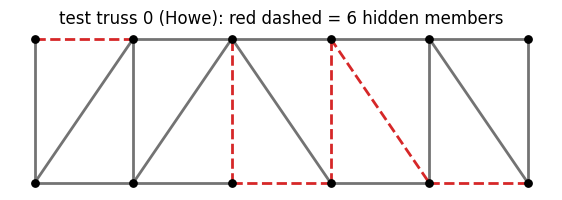

In [4]:
def hide(g, frac, rng):
    """부재의 frac을 가린다. 반환: 보이는 부재, 가린 부재(양성), 같은 수의 음성(트러스마다)"""
    E = g["edges"]; idx = rng.permutation(E.size(1)); k = int(frac * E.size(1))
    hidden, visible = E[:, idx[:k]], E[:, idx[k:]]
    gid = g["batch"][g["nonmem"][0].numpy()]
    neg = []
    for t, cnt in zip(*np.unique(g["batch"][hidden[0].numpy()], return_counts=True)):
        cand = np.where(gid == t)[0]
        neg += list(rng.choice(cand, size=cnt, replace=False))
    return visible, hidden, g["nonmem"][:, neg]

visible, hidden, neg = hide(te_g, 0.2, rng)
vis_ud = to_undirected(visible)
print(f"시험: 보이는 부재 {visible.size(1)} · 가린 부재(양성) {hidden.size(1)} · 음성 {neg.size(1)}")

t0 = test_set[0]                                                    # 첫 시험 트러스 그림
h0 = [tuple(e) for e in hidden.t().tolist() if e[0] < len(t0["pos"]) and e[1] < len(t0["pos"])]
v0 = [tuple(e) for e in visible.t().tolist() if e[0] < len(t0["pos"]) and e[1] < len(t0["pos"])]
fig, ax = plt.subplots(figsize=(7, 2.4))
draw(ax, t0["pos"], v0, f"test truss 0 ({t0['kind']}): red dashed = {len(h0)} hidden members")
for u, v in h0: ax.plot(*zip(t0["pos"][u], t0["pos"][v]), color="tab:red", lw=2, ls="--")
plt.show()

## 4. 기준선 — 학습 없이 세기 (강의노트 2절)
보이는 부재만으로 만든 그래프에서 점수를 매깁니다.
- **공통 이웃(CN) · Jaccard · Adamic–Adar(AA)**: 강의노트의 국소 휴리스틱
- **Katz**: 모든 길이의 경로 수를 $\beta^\ell$ 로 할인해 합산 — 트러스마다 닫힌 식 $S = (I - \beta A)^{-1} - I$. **$\beta < 1/\lambda_{\max}$ 일 때만** 수렴(강의노트 2.2절)
- **거리**: 가까운 절점일수록 높은 점수(부재는 이웃 절점끼리 잇는다는 기하 지식)
- **차수 결손**: 두 절점의 보이는 부재 수가 적을수록 높은 점수 — 부재가 빠진 절점은 연결이 모자라다(정정 트러스 지식)

채점은 **AUC**(양성–음성 대결 승률) · **AP** · **Hits@10**(양성이 '10번째로 높은 음성 점수'보다 높은 비율, OGB 방식) — 강의노트 7절.

In [5]:
def heuristic_scores(g, visible, beta=0.1):
    N = g["x"].size(0)
    G = nx.Graph(); G.add_nodes_from(range(N)); G.add_edges_from(visible.t().tolist())
    A = nx.to_numpy_array(G, nodelist=range(N))
    katz, lam = np.zeros((N, N)), []
    for t in np.unique(g["batch"]):                                  # 트러스마다 Katz 닫힌 식
        ix = np.where(g["batch"] == t)[0]; At = A[np.ix_(ix, ix)]
        lam.append(max(abs(np.linalg.eigvals(At))))
        katz[np.ix_(ix, ix)] = np.linalg.inv(np.eye(len(ix)) - beta * At) - np.eye(len(ix))
    assert beta < 1 / max(lam), "Katz 급수가 발산한다: β < 1/λmax 여야 한다"
    pos = g["pos"]
    def score(pairs, kind):
        out = []
        for u, v in pairs.t().tolist():
            cn = list(nx.common_neighbors(G, u, v))
            if kind == "공통 이웃": out.append(len(cn))
            elif kind == "Jaccard": un = len(set(G[u]) | set(G[v])); out.append(len(cn) / un if un else 0.0)
            elif kind == "Adamic–Adar": out.append(sum(1 / math.log(G.degree(c)) for c in cn if G.degree(c) > 1))
            elif kind == "Katz": out.append(katz[u, v])
            elif kind == "거리": out.append(-float(np.hypot(*(pos[u] - pos[v]))))
            elif kind == "차수 결손": out.append(-(G.degree(u) + G.degree(v)))
        return np.array(out, dtype=float)
    score.lam_max = max(lam)
    return score

def auc_ap(sp, sn):
    y = np.r_[np.ones(len(sp)), np.zeros(len(sn))]; s = np.r_[sp, sn]
    return roc_auc_score(y, s), average_precision_score(y, s)

def hits_at_k(sp, sn, k=10):
    return float(np.mean(sp > np.sort(sn)[-k]))                       # 양성 > K번째로 높은 음성 점수

HEUR = ("공통 이웃", "Jaccard", "Adamic–Adar", "Katz", "거리", "차수 결손")
score_h = heuristic_scores(te_g, visible)
print(f"Katz: β = 0.1, 시험 트러스 λmax 최대 {score_h.lam_max:.2f} → β 한계 1/λmax = {1 / score_h.lam_max:.3f}")
scorers = {k: (lambda p, k=k: score_h(p, k)) for k in HEUR}            # 방법 이름 → 점수 함수
basic = lambda f: {k: round(v, 3) for k, v in zip(("AUC", "AP", "Hits@10"), (*auc_ap(f(hidden), f(neg)), hits_at_k(f(hidden), f(neg))))}
pd.DataFrame({k: basic(f) for k, f in scorers.items()}).T.round(3)

Katz: β = 0.1, 시험 트러스 λmax 최대 3.80 → β 한계 1/λmax = 0.263


,AUC,AP,Hits@10
공통 이웃,0.804,0.755,0.147
Jaccard,0.834,0.825,0.653
Adamic–Adar,0.804,0.754,0.421
Katz,0.745,0.739,0.337
거리,0.985,0.983,0.937
차수 결손,0.646,0.598,0.074


## 5. GAE · VGAE — 완전한 트러스에서 부재를 가려 가며 배운다 (강의노트 4 · 5 · 7.4절)
- **GAE**: 강의노트 9.1절과 같은 2층 GCN 인코더 + 내적 디코더 · **VGAE**: 인코더가 $\mu$, $\log\sigma$ 를 내고 손실 = BCE + KL/N (강의노트 5절)
- 학습 트러스 40동은 도면이 완전하다 → 에폭마다 부재 20%를 무작위로 가려 **감독 엣지**로, 나머지를 **메시지 엣지**로 쓴다(`disjoint_train_ratio` 와 같은 생각)
- 음성 = 같은 트러스 안의 비부재 쌍(학습 트러스는 완전하므로 진짜 음성)
- 피처에 **보이는 부재 수(차수)/4** 를 더한다 — 메시지 엣지가 바뀔 때마다 다시 계산

In [6]:
def feats(g, msg_ud):
    return torch.cat([g["x"], (degree(msg_ud[0], g["x"].size(0)) / 4).view(-1, 1)], 1)

class VEncoder(nn.Module):                                          # VGAE 인코더: 첫 층 공유 → μ, log σ
    def __init__(self, i, o):
        super().__init__(); self.c1, self.mu, self.ls = GCNConv(i, 2 * o), GCNConv(2 * o, o), GCNConv(2 * o, o)
    def forward(self, x, ei):
        h = self.c1(x, ei).relu(); return self.mu(h, ei), self.ls(h, ei)

def train_ae(tr_g, variational=False, epochs=300, mask=0.2, seed=0):
    pyg.seed_everything(seed)
    model = VGAE(VEncoder(4, 32)) if variational else GAE(GCN(4, 64, num_layers=2, out_channels=32))
    opt = torch.optim.Adam(model.parameters(), lr=0.01)
    E, NM = tr_g["edges"], tr_g["nonmem"]; losses = []
    for epoch in range(1, epochs + 1):
        model.train(); opt.zero_grad()
        m = torch.rand(E.size(1)) < mask                              # 이번 에폭에 가릴 부재
        sup, msg_ud = E[:, m], to_undirected(E[:, ~m])                # 감독 엣지 · 메시지 엣지
        z = model.encode(feats(tr_g, msg_ud), msg_ud)
        negs = NM[:, torch.randint(0, NM.size(1), (sup.size(1),))]    # 같은 수의 음성
        loss = model.recon_loss(z, sup, negs)                         # BCE (양성 평균 + 음성 평균)
        if variational: loss = loss + model.kl_loss() / tr_g["x"].size(0)   # + KL/N
        loss.backward(); opt.step(); losses.append(float(loss))
        if epoch % 100 == 0:                                          # 가리는 부재가 매번 달라 손실이 출렁인다 → 100에폭 평균
            print(f"  epoch {epoch - 99:3d}–{epoch} | 평균 loss {np.mean(losses[-100:]):.3f}")
    model.eval(); return model

def ae_scorer(model, g, visible):
    vud = to_undirected(visible)
    with torch.no_grad():
        z = model.encode(feats(g, vud), vud)                          # 시험 트러스: 보이는 부재만 입력 (VGAE는 평가 때 z = μ)
    return lambda p: (z[p[0]] * z[p[1]]).sum(1).numpy()               # 내적 점수(로짓)

t = time.time()
print("GAE"); gae_model = train_ae(tr_g)
print("VGAE"); vgae_model = train_ae(tr_g, variational=True)
print(f"⏱ 학습 {time.time() - t:.1f}초")
scorers["GAE"] = ae_scorer(gae_model, te_g, visible)
scorers["VGAE"] = ae_scorer(vgae_model, te_g, visible)
pd.DataFrame({k: basic(f) for k, f in scorers.items()}).T.round(3)

GAE


  epoch   1–100 | 평균 loss 1.012


  epoch 101–200 | 평균 loss 0.857


  epoch 201–300 | 평균 loss 0.834
VGAE


  epoch   1–100 | 평균 loss 1.363


  epoch 101–200 | 평균 loss 0.987


  epoch 201–300 | 평균 loss 0.949
⏱ 학습 3.2초


,AUC,AP,Hits@10
공통 이웃,0.804,0.755,0.147
Jaccard,0.834,0.825,0.653
Adamic–Adar,0.804,0.754,0.421
Katz,0.745,0.739,0.337
거리,0.985,0.983,0.937
차수 결손,0.646,0.598,0.074
GAE,0.941,0.907,0.800
VGAE,0.940,0.909,0.811


## 6. 채점 두 가지 — 쉬운 음성 대 어려운 음성 (강의노트 7.5절)
- 위 표의 음성은 **무작위** 비부재 쌍 → 대부분 멀리 떨어진 쌍이라 '거리' 하나로도 잘 가린다(쉬운 음성)
- **어려운 질문**: 대각재가 빠진 패널에서 **두 대각선 중 어느 것**이 부재였나? 두 대각선은 길이가 같고, 공통 이웃 수도 같다
- 채점: 숨긴 대각재와 같은 패널의 반대 대각선을 짝지어 대결 → 숨긴 대각재가 이긴 비율(비기면 ½)

In [7]:
def orientation_pairs(g, hidden):
    other = {tuple(sorted(d)): tuple(sorted(o)) for d, o in zip(g["diag"], g["other"])}
    hid = [tuple(sorted(e)) for e in hidden.t().tolist() if tuple(sorted(e)) in other]
    return torch.tensor(hid).t(), torch.tensor([other[e] for e in hid]).t()

def win_rate(sp, sn): return float(np.mean((sp > sn) + 0.5 * (sp == sn)))

dp, dn = orientation_pairs(te_g, hidden)
print("숨긴 대각재", dp.size(1), "개")
pd.DataFrame({k: basic(f) | {"대각재 방향 승률": round(win_rate(f(dp), f(dn)), 3)} for k, f in scorers.items()}).T

숨긴 대각재 20 개


,AUC,AP,Hits@10,대각재 방향 승률
공통 이웃,0.804,0.755,0.147,0.500
Jaccard,0.834,0.825,0.653,0.600
Adamic–Adar,0.804,0.754,0.421,0.450
Katz,0.745,0.739,0.337,0.325
거리,0.985,0.983,0.937,0.500
차수 결손,0.646,0.598,0.074,0.675
GAE,0.941,0.907,0.800,0.650
VGAE,0.940,0.909,0.811,0.700


**읽는 법**
- 무작위 음성에서는 **거리**가 가장 높다 → 높은 AUC가 곧 어려운 쌍도 잘 가린다는 뜻은 아니다
- 대각재 방향에서 거리 · 공통 이웃은 0.5(구별 못 함) — 직사각형 패널의 두 대각선은 길이도 공통 이웃 수도 같다(대칭 때문에 점수가 같아지는 문제, 강의노트 6.4절과 같은 종류)
- **Adamic–Adar · Katz는 0.5보다 낮다** — 반대 대각선의 공통 이웃이 바로 '부재가 빠져 차수가 줄어든' 두 절점이라 AA가 가산점을 주고, 반대 대각선 쪽 절점들은 연결이 더 많아 Katz의 경로 수도 많다 → 오히려 반대쪽을 고른다
- **Jaccard · 차수 결손 · GAE · VGAE는 0.5보다 높다** — 빠진 부재의 양 끝 절점은 연결이 하나씩 모자라다는 구조 신호를 쓴다(Jaccard는 합친 이웃 수로 나누므로 연결이 적은 쌍이 높은 점수를 받는다)
- **AUC와 Hits@10의 순위가 다르다** — 예: 차수 결손은 AUC가 0.6대인데 Hits@10은 0.1 아래. 상위권에 정답을 올리는 능력은 AUC만으로 알 수 없다(강의노트 7.3절)

## 7. 구조 검증 — 예측으로 복원한 트러스를 해석한다
1. 시험 트러스에서 **보이는 부재만** 남기면 $m + r < 2j$ → 강성행렬이 특이(불안정) → 해석 불가
2. 빠진 개수 $k = 2j - r - m_{\text{보임}}$ 만큼 부재를 추가한다. 후보는 **길이가 패널 대각선 이하인 절점 쌍**(그보다 긴 부재는 없다는 기하 조건), 그중 점수 상위 $k$ 개
3. **직접강성법**으로 처짐을 계산해 원래 트러스와 비교 (강재 $E$ = 200 GPa, 단면적 $A$ = 2000 mm², 아래현 내부 절점마다 10 kN)
4. 시험 트러스 20동 전체에 대해 **완전 복원**(빠진 부재를 모두 맞힘) · **안정**(강성행렬이 정칙)인 트러스 수를 센다

In [8]:
def solve_truss(pos, members, n, P=10e3, E=200e9, A=2e-3):
    """2D 트러스 직접강성법. 왼쪽 아래 핀 · 오른쪽 아래 롤러, 아래현 내부 절점마다 P(N) 하향.
    반환: (최대 처짐 mm, None) 또는 (None, 강성행렬 계수 부족 수)"""
    N = len(pos); K = np.zeros((2 * N, 2 * N))
    for u, v in members:
        d = pos[v] - pos[u]; L = np.hypot(*d); c, s = d / L
        T = np.array([-c, -s, c, s]); idx = [2 * u, 2 * u + 1, 2 * v, 2 * v + 1]
        K[np.ix_(idx, idx)] += E * A / L * np.outer(T, T)             # 부재 강성을 전체 강성행렬에 조립
    free = [i for i in range(2 * N) if i not in (0, 1, 2 * n + 1)]   # 핀(x, y) · 롤러(y) 고정
    Kff = K[np.ix_(free, free)]; deficit = len(free) - np.linalg.matrix_rank(Kff)
    if deficit > 0: return None, deficit                             # 불안정(기구)
    F = np.zeros(2 * N); F[[2 * i + 1 for i in range(1, n)]] = -P
    u = np.zeros(2 * N); u[free] = np.linalg.solve(Kff, F[free])
    return -u[1::2].min() * 1e3, None

def restore_all(g, tset, visible, hidden, scorer):
    """시험 트러스마다 빠진 개수 k 만큼, 길이 조건을 만족하는 후보 중 점수 상위 k 쌍을 추가하고 해석한다"""
    out = []
    for t_id, tr in enumerate(tset):
        off = int(np.where(g["batch"] == t_id)[0][0]); N = len(tr["pos"])
        loc = lambda E: {tuple(sorted((u - off, v - off))) for u, v in E.t().tolist() if off <= u < off + N}
        vis, hid = loc(visible), loc(hidden)
        k = 2 * N - 3 - len(vis)                                      # Maxwell: 빠진 부재 수
        if k == 0: continue                                           # 가린 부재가 없는 트러스는 건너뜀
        L = 1.05 * math.hypot(tr["w"], tr["h"])                       # 가장 긴 부재 = 패널 대각선
        cand = [(u, v) for u in range(N) for v in range(u + 1, N)
                if (u, v) not in vis and np.hypot(*(tr["pos"][u] - tr["pos"][v])) <= L]
        s = scorer(torch.tensor([[u + off for u, v in cand], [v + off for u, v in cand]]))
        top = {cand[i] for i in np.argsort(-s, kind="stable")[:k]}   # 점수 상위 k 쌍
        d0, _ = solve_truss(tr["pos"], tr["mem"], tr["n"])            # 원래 트러스 처짐
        d1, lack = solve_truss(tr["pos"], list(vis | top), tr["n"])   # 복원한 트러스 처짐
        out.append(dict(트러스=t_id, k=k, 맞힘=len(top & hid), 완전복원=top == hid, 안정=d1 is not None,
                        처짐_원래=round(d0, 3), 처짐_복원=None if d1 is None else round(d1, 3), vis=vis, hid=hid, top=top))
    return pd.DataFrame(out)

def full_row(f):
    """한 방법의 모든 지표: 무작위 음성 AUC · AP · Hits@10, 대각재 방향, 트러스 복원"""
    df = restore_all(te_g, test_set, visible, hidden, f)
    return basic(f) | {"대각재 방향 승률": round(win_rate(f(dp), f(dn)), 3), "완전 복원": f"{int(df.완전복원.sum())}/{len(df)}",
                       "안정": f"{int(df.안정.sum())}/{len(df)}", "맞힌 부재 비율": round(df.맞힘.sum() / df.k.sum(), 3)}

pd.DataFrame({k: full_row(f) for k, f in scorers.items()}).T.round(3)

,AUC,AP,Hits@10,대각재 방향 승률,완전 복원,안정,맞힌 부재 비율
공통 이웃,0.804,0.755,0.147,0.5,0/20,0/20,0.337
Jaccard,0.834,0.825,0.653,0.6,1/20,1/20,0.432
Adamic–Adar,0.804,0.754,0.421,0.45,0/20,0/20,0.368
Katz,0.745,0.739,0.337,0.325,0/20,0/20,0.274
거리,0.985,0.983,0.937,0.5,8/20,9/20,0.863
차수 결손,0.646,0.598,0.074,0.675,2/20,3/20,0.621
GAE,0.941,0.907,0.8,0.65,0/20,0/20,0.495
VGAE,0.94,0.909,0.811,0.7,2/20,2/20,0.516


**읽는 법** — GAE · VGAE는 무작위 음성 AUC가 높았지만(5–6절), 가까운 후보 사이에서 고르게 하면 트러스를 거의 복원하지 못한다(위 표의 완전 복원 수). 이유 둘:
- 학습 음성이 대부분 **멀리 떨어진 쌍**(쉬운 음성)이라, 가까운 쌍끼리 가르는 법을 배우지 못했다(강의노트 7.5절)
- **내적 디코더**는 두 임베딩이 '같은 방향'인지만 본다. 격자처럼 이웃이 여러 방향으로 퍼진 트러스의 연결을 내적 하나로 담기 어렵다

## 8. 고쳐 보기 ① — MLP 디코더 + 어려운 음성 (강의노트 4.3 · 7.5절)
두 가지만 바꾼다. 인코더(2층 GCN)와 학습 방식(부재를 가려 가며 학습)은 그대로.
1. **디코더를 MLP로**: 두 절점의 임베딩과 **좌표 차** $(\Delta x, \Delta y)$ 를 받아 점수를 낸다(강의노트 4.3절 '디코더를 MLP로 대체'). 쌍은 (아래·왼쪽 → 위·오른쪽) 순서로 맞춰 방향이 일관되게
2. **어려운 음성 섞기**: 학습 음성의 절반을 '길이가 패널 대각선 이하인 비부재 쌍'(예: 반대 대각선)에서 뽑는다. 학습 트러스는 도면이 완전하므로 이 쌍들은 진짜 음성이다

In [9]:
class PairMLP(nn.Module):
    """링크 디코더 = 작은 MLP: [z(아래·왼쪽 절점), z(위·오른쪽 절점), 좌표 차] → 점수(로짓)"""
    def __init__(self, d):
        super().__init__(); self.mlp = nn.Sequential(nn.Linear(2 * d + 2, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(self, z, x, e):
        u, v = e
        swap = (x[u, 1] > x[v, 1]) | ((x[u, 1] == x[v, 1]) & (x[u, 0] > x[v, 0]))   # 쌍의 순서 통일
        a, b = torch.where(swap, v, u), torch.where(swap, u, v)
        return self.mlp(torch.cat([z[a], z[b], x[b, :2] - x[a, :2]], 1)).view(-1)

def near_nonmembers(g, tset):
    """어려운 음성 후보: 같은 트러스 안에서 길이가 패널 대각선 이하인 비부재 쌍"""
    out = []
    for t_id, tr in enumerate(tset):
        off = int(np.where(g["batch"] == t_id)[0][0]); N = len(tr["pos"]); L = 1.05 * math.hypot(tr["w"], tr["h"])
        mem = {tuple(sorted(e)) for e in tr["mem"]}
        out += [(u + off, v + off) for u in range(N) for v in range(u + 1, N)
                if (u, v) not in mem and np.hypot(*(tr["pos"][u] - tr["pos"][v])) <= L]
    return torch.tensor(out).t()

def train_mlp(tr_g, tr_set, epochs=300, mask=0.2, seed=0):
    pyg.seed_everything(seed)
    enc, dec = GCN(4, 64, num_layers=2, out_channels=32), PairMLP(32)      # 인코더는 5절과 같은 2층 GCN
    opt = torch.optim.Adam(list(enc.parameters()) + list(dec.parameters()), lr=0.01)
    E, NM, X, HARD = tr_g["edges"], tr_g["nonmem"], tr_g["x"], near_nonmembers(tr_g, tr_set)
    for epoch in range(1, epochs + 1):
        opt.zero_grad()
        m = torch.rand(E.size(1)) < mask
        sup, msg_ud = E[:, m], to_undirected(E[:, ~m])                # 감독 엣지 · 메시지 엣지
        z = enc(feats(tr_g, msg_ud), msg_ud)
        h = int(0.5 * sup.size(1))                                    # 음성의 절반은 어려운(가까운) 쌍
        negs = torch.cat([NM[:, torch.randint(0, NM.size(1), (sup.size(1) - h,))],
                          HARD[:, torch.randint(0, HARD.size(1), (h,))]], 1)
        sp, sn = dec(z, X, sup), dec(z, X, negs)
        loss = nn.functional.binary_cross_entropy_with_logits(torch.cat([sp, sn]), torch.cat([torch.ones_like(sp), torch.zeros_like(sn)]))
        loss.backward(); opt.step()
    return enc, dec

def mlp_scorer(enc, dec, g, visible):
    vud = to_undirected(visible)
    with torch.no_grad():
        z = enc(feats(g, vud), vud)
    return lambda p: dec(z, g["x"], p).detach().numpy()

t = time.time()
enc, dec = train_mlp(tr_g, train_set)
print(f"⏱ 학습 {time.time() - t:.1f}초")
scorers["GNN + MLP 디코더"] = mlp_scorer(enc, dec, te_g, visible)
pd.DataFrame({"GNN + MLP 디코더": full_row(scorers["GNN + MLP 디코더"])}).T.round(3)

⏱ 학습 1.3초


,AUC,AP,Hits@10,대각재 방향 승률,완전 복원,안정,맞힌 부재 비율
GNN + MLP 디코더,0.995,0.995,1.0,0.65,8/20,10/20,0.832


시험 트러스 7 (Pratt, 패널 6) — 빠진 부재 k = 7개, 맞힌 부재 7개
  원래 트러스          : 최대 처짐 8.708 mm
  보이는 부재만        : 불안정 (강성행렬 계수가 7만큼 모자람)
  상위 k 로 복원한 트러스: 최대 처짐 8.708 mm


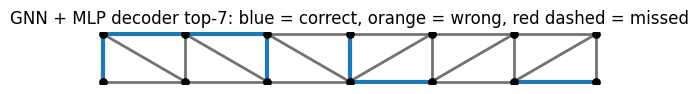

In [10]:
df = restore_all(te_g, test_set, visible, hidden, scorers["GNN + MLP 디코더"])   # 복원 예: 완전 복원한 트러스 중 빠진 부재가 가장 많은 것
row = (df[df.완전복원] if df.완전복원.any() else df).sort_values("k", kind="stable").iloc[-1]
tr = test_set[int(row.트러스)]
d_vis, lack = solve_truss(tr["pos"], list(row.vis), tr["n"])
print(f"시험 트러스 {row.트러스} ({tr['kind']}, 패널 {tr['n']}) — 빠진 부재 k = {row.k}개, 맞힌 부재 {row.맞힘}개")
print(f"  원래 트러스          : 최대 처짐 {row.처짐_원래:.3f} mm")
print(f"  보이는 부재만        : 불안정 (강성행렬 계수가 {lack}만큼 모자람)")
print(f"  상위 k 로 복원한 트러스: " + (f"최대 처짐 {row.처짐_복원:.3f} mm" if row.안정 else "불안정"))
fig, ax = plt.subplots(figsize=(7, 2.6))
draw(ax, tr["pos"], list(row.vis), f"GNN + MLP decoder top-{row.k}: blue = correct, orange = wrong, red dashed = missed")
for u, v in row.top:
    ax.plot(*zip(tr["pos"][u], tr["pos"][v]), color="tab:blue" if (u, v) in row.hid else "tab:orange", lw=3)
for u, v in row.hid - row.top:
    ax.plot(*zip(tr["pos"][u], tr["pos"][v]), color="tab:red", lw=2, ls="--")
plt.show()

## 9. 고쳐 보기 ② — SEAL 간이판: 두 절점 주변을 통째로 (강의노트 6절)
GAE류가 두 절점을 **각자** 임베딩해 점수를 매긴다면, SEAL은 두 절점 주변의 **부분그래프 한 장**을 보고 "부재 있음/없음"을 분류한다.
1. **부분그래프**: 대상 두 절점과 $h$ 홉 이웃(보이는 부재로만). 4절 표처럼 이 데이터에서는 AA가 CN보다 낫지 않으므로 강의노트 6절의 규칙(AA가 CN보다 나으면 $h=2$, 아니면 $h=1$ — 원래는 검증셋으로 판단)대로 **$h = 1$**
2. **DRNL 라벨**: 대상 = 1, 나머지는 (대상 x까지, 대상 y까지) 거리로 매긴 정수(상대 대상 절점을 지우고 잰다, 닿지 않으면 0) → **원-핫**으로 바꿔 노드 피처 옆에 붙인다
3. **그래프 분류기**: GCN 3층 → 평균 · 최대 풀링 → MLP. 교재 DGCNN의 정렬 풀링 · 1D 합성곱 대신 단순한 풀링을 쓴 **간이판**이다
4. 학습 데이터: 학습 트러스에서 부재 20%를 가린 경우를 8번 만들어, 가린 부재(양성)와 같은 수의 음성(절반은 가까운 비부재)의 부분그래프를 모은다

In [11]:
MAXZ = 8                                                             # DRNL 라벨 상한(넘으면 MAXZ로)
def bfs(adj, src, banned):
    dist, q = {src: 0}, deque([src])
    while q:
        a = q.popleft()
        for b in adj[a]:
            if b != banned and b not in dist: dist[b] = dist[a] + 1; q.append(b)
    return dist

def drnl(dx, dy):                                                    # 강의노트 6.1절 식, 닿지 않으면 0
    if dx is None or dy is None: return 0
    d = dx + dy; return 1 + min(dx, dy) + (d // 2) * (d // 2 + d % 2 - 1)

def adjacency(msg, N):
    adj = {i: set() for i in range(N)}
    for a, b in msg.t().tolist(): adj[a].add(b); adj[b].add(a)
    return adj

def enclosing_subgraph(adj, xf, u, v, h=1, y=0):
    """대상 u, v 의 h홉 부분그래프 → PyG Data (노드 피처 = DRNL 원-핫 + 절점 피처)"""
    nodes, front = {u, v}, {u, v}
    for _ in range(h):
        front = {b for a in front for b in adj[a]} - nodes; nodes |= front
    nodes = sorted(nodes); ix = {n: i for i, n in enumerate(nodes)}; S = set(nodes)
    sub = {n: (adj[n] & S) - ({v} if n == u else {u} if n == v else set()) for n in nodes}   # 대상 엣지는 빼고
    du, dv = bfs(sub, u, banned=v), bfs(sub, v, banned=u)            # 상대 대상 절점을 지우고 거리
    z = torch.tensor([1 if n in (u, v) else min(drnl(du.get(n), dv.get(n)), MAXZ) for n in nodes])
    ei = torch.tensor([(ix[a], ix[b]) for a in nodes for b in sub[a]], dtype=torch.long).reshape(-1, 2).t()
    x = torch.cat([nn.functional.one_hot(z, MAXZ + 1).float(), xf[nodes]], 1)
    return Data(x=x, edge_index=ei, y=torch.tensor([float(y)]))

class SEALLite(nn.Module):
    def __init__(self, d_in, hid=32):
        super().__init__(); self.gnn = GCN(d_in, hid, num_layers=3)
        self.out = nn.Sequential(nn.Linear(2 * hid, hid), nn.ReLU(), nn.Linear(hid, 1))
    def forward(self, d):
        hh = self.gnn(d.x, d.edge_index)
        return self.out(torch.cat([global_mean_pool(hh, d.batch), global_max_pool(hh, d.batch)], 1)).view(-1)

def train_seal(tr_g, tr_set, h=1, masks=8, mask=0.2, epochs=30, seed=0):
    pyg.seed_everything(seed); r = np.random.default_rng(seed)
    E, NM, HARD, N = tr_g["edges"], tr_g["nonmem"], near_nonmembers(tr_g, tr_set), tr_g["x"].size(0)
    data = []
    for _ in range(masks):                                           # 가림 8번 → 부분그래프 데이터셋
        m = torch.tensor(r.random(E.size(1)) < mask); sup, msg = E[:, m], E[:, ~m]
        adj, xf, k = adjacency(msg, N), feats(tr_g, to_undirected(msg)), sup.size(1)
        negs = torch.cat([NM[:, torch.tensor(r.integers(0, NM.size(1), k - k // 2))],
                          HARD[:, torch.tensor(r.integers(0, HARD.size(1), k // 2))]], 1)
        data += [enclosing_subgraph(adj, xf, u, v, h, 1) for u, v in sup.t().tolist()]
        data += [enclosing_subgraph(adj, xf, u, v, h, 0) for u, v in negs.t().tolist()]
    model = SEALLite(data[0].x.size(1)); opt = torch.optim.Adam(model.parameters(), lr=0.005)
    for epoch in range(epochs):
        model.train()
        for d in DataLoader(data, batch_size=64, shuffle=True):
            opt.zero_grad(); nn.functional.binary_cross_entropy_with_logits(model(d), d.y).backward(); opt.step()
    model.eval(); return model, len(data)

def seal_scorer(model, g, visible, h=1):
    adj, xf = adjacency(visible, g["x"].size(0)), feats(g, to_undirected(visible))
    def f(pairs):
        ds = [enclosing_subgraph(adj, xf, u, v, h) for u, v in pairs.t().tolist()]
        with torch.no_grad():
            return torch.cat([model(d) for d in DataLoader(ds, batch_size=256)]).numpy()
    return f

t = time.time()
seal_model, n_sub = train_seal(tr_g, train_set)
print(f"학습 부분그래프 {n_sub}개 | ⏱ 학습 {time.time() - t:.1f}초")
scorers["SEAL 간이판"] = seal_scorer(seal_model, te_g, visible)

학습 부분그래프 3562개 | ⏱ 학습 12.0초


### 한 표로 비교 — 모든 방법 (seed 0)

In [12]:
pd.DataFrame({k: full_row(f) for k, f in scorers.items()}).T.round(3)

,AUC,AP,Hits@10,대각재 방향 승률,완전 복원,안정,맞힌 부재 비율
공통 이웃,0.804,0.755,0.147,0.5,0/20,0/20,0.337
Jaccard,0.834,0.825,0.653,0.6,1/20,1/20,0.432
Adamic–Adar,0.804,0.754,0.421,0.45,0/20,0/20,0.368
Katz,0.745,0.739,0.337,0.325,0/20,0/20,0.274
거리,0.985,0.983,0.937,0.5,8/20,9/20,0.863
차수 결손,0.646,0.598,0.074,0.675,2/20,3/20,0.621
GAE,0.941,0.907,0.8,0.65,0/20,0/20,0.495
VGAE,0.94,0.909,0.811,0.7,2/20,2/20,0.516
GNN + MLP 디코더,0.995,0.995,1.0,0.65,8/20,10/20,0.832
SEAL 간이판,0.945,0.935,0.884,0.8,7/20,9/20,0.747


## 10. 시드 3개로 다시 — 한 번 실행한 숫자는 흔들린다 (강의노트 7.5절)
트러스 생성 · 가리기 · 학습을 시드 0, 1, 2로 반복해 평균 ± 표준편차를 봅니다. (이 노트북을 만든 로컬 CPU에서 약 50초)

In [13]:
t = time.time(); runs = []
for seed in (0, 1, 2):                                                # 시드마다 트러스 생성부터 다시
    r = np.random.default_rng(seed); pyg.seed_everything(seed)
    trs, tes = make_set(40, 0, r), make_set(20, 1, r)
    trg, teg = union(trs), union(tes)
    vis_s, hid_s, neg_s = hide(teg, 0.2, r)
    sh = heuristic_scores(teg, vis_s)
    fs = {k: (lambda p, k=k: sh(p, k)) for k in HEUR}
    with contextlib.redirect_stdout(io.StringIO()):                   # 학습 로그는 숨긴다
        fs["GAE"] = ae_scorer(train_ae(trg, seed=seed), teg, vis_s)
        fs["VGAE"] = ae_scorer(train_ae(trg, variational=True, seed=seed), teg, vis_s)
        fs["GNN + MLP 디코더"] = mlp_scorer(*train_mlp(trg, trs, seed=seed), teg, vis_s)
        fs["SEAL 간이판"] = seal_scorer(train_seal(trg, trs, seed=seed)[0], teg, vis_s)
    dp_s, dn_s = orientation_pairs(teg, hid_s)
    for name, f in fs.items():
        sp, sn = f(hid_s), f(neg_s); rec = restore_all(teg, tes, vis_s, hid_s, f)
        runs.append(dict(seed=seed, 방법=name, AUC=auc_ap(sp, sn)[0], Hits10=hits_at_k(sp, sn),
                         방향승률=win_rate(f(dp_s), f(dn_s)), 완전복원비율=rec.완전복원.mean()))
summary = pd.DataFrame(runs).groupby("방법", sort=False)[["AUC", "Hits10", "방향승률", "완전복원비율"]].agg(["mean", "std"]).round(3)
print(f"⏱ {time.time() - t:.1f}초")
summary

⏱ 47.8초


AUC        Hits10          방향승률        완전복원비율       
                mean    std   mean    std   mean    std   mean    std
방법                                                                   
공통 이웃          0.768  0.034  0.145  0.005  0.493  0.012  0.000  0.000
Jaccard        0.800  0.031  0.500  0.138  0.704  0.091  0.017  0.029
Adamic–Adar    0.771  0.029  0.263  0.137  0.348  0.105  0.000  0.000
Katz           0.722  0.028  0.226  0.101  0.271  0.059  0.000  0.000
거리             0.986  0.001  0.967  0.032  0.500  0.000  0.267  0.126
차수 결손          0.683  0.033  0.081  0.013  0.769  0.085  0.050  0.050
GAE            0.922  0.023  0.705  0.085  0.761  0.099  0.000  0.000
VGAE           0.918  0.021  0.682  0.123  0.805  0.093  0.033  0.058
GNN + MLP 디코더  0.992  0.005  0.994  0.011  0.802  0.131  0.467  0.115
SEAL 간이판       0.953  0.010  0.894  0.028  0.769  0.091  0.217  0.115

In [14]:
print(f"⏱ 노트북 전체 {time.time() - T0:.0f}초")

⏱ 노트북 전체 65초


## 11. 정리
- 트러스 = 그래프(절점 · 부재) → **누락 부재 찾기 = 링크 예측**. 몇 개가 빠졌는지는 Maxwell 식($2j - r - m$), 어느 것인지는 모델의 몫
- **무작위 음성 AUC만 보면** 거리와 GAE · VGAE가 모두 좋아 보인다(5–6절). 그러나 가까운 후보 중에서 고르는 실제 복원에서 GAE · VGAE는 거의 쓸모가 없었다(7절) → 링크 예측 지표와 구조적 쓸모는 별개이고, **구조해석으로 검증**해야 한다
- 대칭인 두 대각선은 거리 · 공통 이웃으로 가를 수 없고, Adamic–Adar · Katz는 오히려 반대쪽을 고른다. '연결이 모자란 절점'이라는 구조 신호(차수 결손 · Jaccard)가 단서가 된다
- **디코더를 MLP로**(좌표 차 포함) 바꾸고 음성의 절반을 가까운 비부재로 뽑거나(8절), **SEAL처럼 두 절점 주변 부분그래프를 DRNL과 함께** 보면(9절) GAE · VGAE보다 복원이 나아진다. 다만 시드 3개 평균으로 거리 휴리스틱을 넘은 것은 MLP 디코더뿐이다(10절) — 음성을 어떻게 뽑고 모델이 무엇을 보느냐가 배우는 것을 정한다
- 이 노트북의 숫자는 각 셀의 출력이다. 다시 실행하면 환경에 따라 소수 셋째 자리가 달라질 수 있고, 시드 사이 표준편차도 크다(10절) — 결론은 여러 시드로 확인할 것

## ✏️ 직접 해 보기 (정답은 없습니다)
1. 8절의 두 변경(MLP 디코더 · 어려운 음성)을 **하나씩만** 켜 보라. 복원 성공에 어느 쪽이 더 크게 기여하는가?
2. 9절 SEAL 간이판의 $h$ 를 2로 바꾸면? DRNL 라벨을 빼고 절점 피처만 쓰면 대각재 방향 승률은 어떻게 변하는가?
3. Katz의 $\beta$ 를 1/λmax 보다 크게 하면 무엇이 일어나는가? Hits@K의 K를 1 · 20으로 바꾸면 순위가 바뀌는가?
4. 7–9절 표에서 '안정' 수가 '완전 복원' 수보다 많을 수 있다. 틀린 부재를 고르고도 안정한 트러스는 처짐이 원래와 얼마나 다른가? 왜 그런가?